# Feature Engineering & Preprocessing Pipeline
**RabTech Academy — Task 03**

A reusable, leakage-aware Scikit-Learn preprocessing workflow for a synthetic Credit Default Risk dataset.

**Objectives**
- Inspect and clean tabular data.
- Split data before fitting preprocessing transformations.
- Impute missing numerical and categorical values.
- Scale numerical features and one-hot encode categorical features.
- Train a baseline model and evaluate it.
- Examine feature importance using mutual information and permutation importance.

> **Dataset note:** `credit-default-risk.csv` is a synthetic educational dataset generated for this task. It contains no real customer records and is not suitable for real lending decisions.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 2. Load the dataset
Place `credit-default-risk.csv` in the same folder as this notebook.

In [2]:
df = pd.read_csv("credit-default-risk.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1200, 12)


,age,annual_income,loan_amount,credit_score,employment_years,debt_to_income_ratio,loan_term_months,education,employment_type,home_ownership,loan_purpose,loan_default
0,25,93809.0,19896.0,672.0,7.8,0.254,36,High School,Self-employed,Mortgage,Home Improvement,0
1,59,45651.0,7907.0,640.0,3.4,0.474,48,Postgraduate,Contract,NaN,Education,1
2,53,61357.0,31161.0,829.0,6.5,0.496,48,High School,Salaried,Mortgage,Vehicle,0
3,42,18000.0,25283.0,674.0,22.9,0.043,60,Graduate,Self-employed,Mortgage,Education,1
4,42,29583.0,18859.0,780.0,8.0,0.170,60,Postgraduate,Salaried,Rent,Education,1


## 3. Initial data inspection

In [3]:
print("Column data types:")
print(df.dtypes)
print("\\nMissing values per column:")
display(df.isna().sum().to_frame("missing_count"))
print("\\nTarget distribution:")
display(df["loan_default"].value_counts(normalize=True).rename("proportion"))

Column data types:
age                       int64
annual_income           float64
loan_amount             float64
credit_score            float64
employment_years        float64
debt_to_income_ratio    float64
loan_term_months          int64
education                object
employment_type          object
home_ownership           object
loan_purpose             object
loan_default              int64
dtype: object
\nMissing values per column:


,missing_count
age,0
annual_income,43
loan_amount,0
credit_score,58
employment_years,62
debt_to_income_ratio,0
loan_term_months,0
education,45
employment_type,36
home_ownership,30


\nTarget distribution:


loan_default
0    0.733333
1    0.266667
Name: proportion, dtype: float64

## 4. Separate features and target
The target is `loan_default`. It is excluded from the preprocessing features.

In [4]:
TARGET = "loan_default"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'annual_income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income_ratio', 'loan_term_months']
Categorical features: ['education', 'employment_type', 'home_ownership', 'loan_purpose']


## 5. Train/test split before preprocessing
This ordering is important. The imputers, scaler, and encoder are fitted only on the training data through the pipeline. The test set is held back until final evaluation, reducing data leakage.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 960
Testing rows: 240


## 6. Correlation analysis (training data only)

Inspect pairwise correlations among numerical predictor features using the training split only. Correlation is a measure of linear association; it does not imply causation. This analysis is exploratory and is not used to fit preprocessing parameters.

,age,annual_income,loan_amount,credit_score,employment_years,debt_to_income_ratio,loan_term_months
age,1.00,0.02,0.02,0.04,0.03,0.00,-0.00
annual_income,0.02,1.00,-0.00,0.03,-0.02,-0.01,-0.06
loan_amount,0.02,-0.00,1.00,0.00,-0.04,-0.08,-0.06
credit_score,0.04,0.03,0.00,1.00,0.00,0.05,-0.00
employment_years,0.03,-0.02,-0.04,0.00,1.00,0.01,0.01
debt_to_income_ratio,0.00,-0.01,-0.08,0.05,0.01,1.00,-0.03
loan_term_months,-0.00,-0.06,-0.06,-0.00,0.01,-0.03,1.00


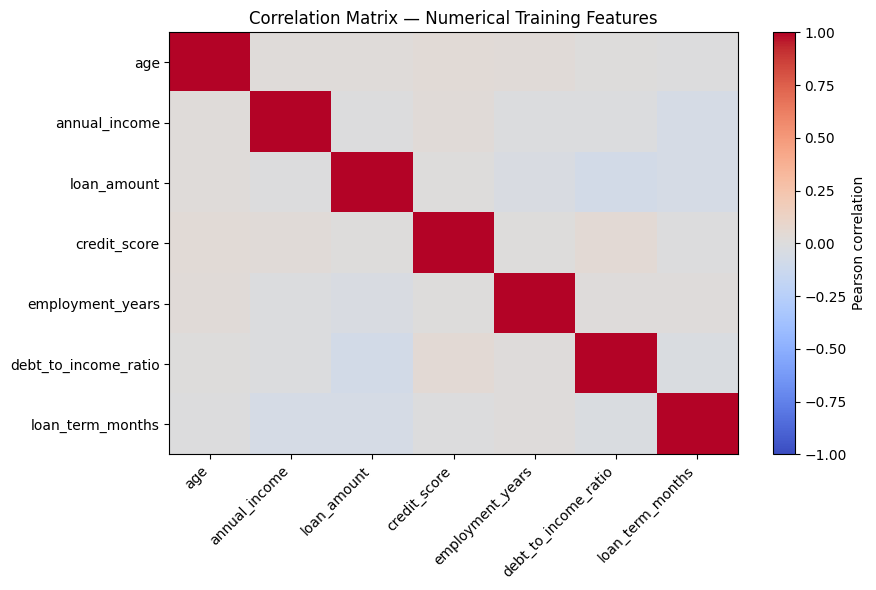

No numerical feature pairs have an absolute correlation of 0.70 or higher.


In [6]:
# Calculate correlations using training predictors only.
train_numeric = X_train[numeric_features]
correlation_matrix = train_numeric.corr(method="pearson")

display(correlation_matrix.round(2))

plt.figure(figsize=(9, 6))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title("Correlation Matrix — Numerical Training Features")
plt.tight_layout()
plt.show()

# List strongly correlated feature pairs (absolute correlation >= 0.70).
strong_pairs = []
for i, col_a in enumerate(correlation_matrix.columns):
    for col_b in correlation_matrix.columns[i + 1:]:
        corr_value = correlation_matrix.loc[col_a, col_b]
        if abs(corr_value) >= 0.70:
            strong_pairs.append({
                "Feature 1": col_a,
                "Feature 2": col_b,
                "Correlation": corr_value
            })

strong_pairs_df = pd.DataFrame(strong_pairs)
if strong_pairs_df.empty:
    print("No numerical feature pairs have an absolute correlation of 0.70 or higher.")
else:
    display(strong_pairs_df.round(3))

## 7. Build reusable preprocessing pipelines
- Numerical: median imputation → standard scaling.
- Categorical: most-frequent imputation → one-hot encoding.
- `handle_unknown="ignore"` allows unseen categories at inference time.

In [7]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

## 8. Train the model
Calling `fit` on the complete pipeline fits all preprocessing steps using only `X_train`.

In [8]:
model_pipeline.fit(X_train, y_train)
print("Pipeline training completed.")

Pipeline training completed.


## 9. Evaluate on the held-out test set

,Metric,Score
0,Accuracy,0.7542
1,Precision,0.6190
2,Recall,0.2031
3,F1-score,0.3059
4,ROC-AUC,0.5863


              precision    recall  f1-score   support

           0       0.77      0.95      0.85       176
           1       0.62      0.20      0.31        64

    accuracy                           0.75       240
   macro avg       0.69      0.58      0.58       240
weighted avg       0.73      0.75      0.71       240



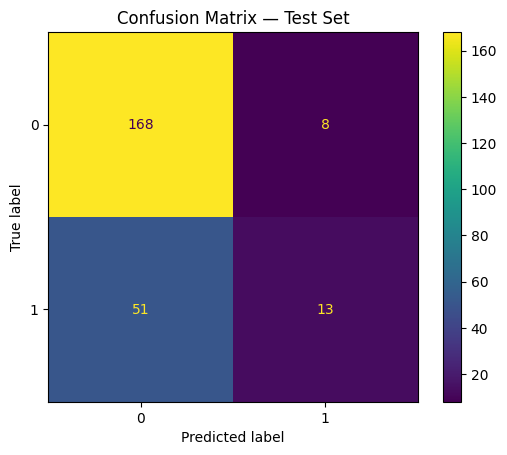

In [9]:
y_pred = model_pipeline.predict(X_test)
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_probability)
    ]
})
display(metrics.round(4))
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix — Test Set")
plt.show()

## 10. Mutual information analysis
Mutual information is calculated on the training data only. Numerical missing values are median-imputed and categorical values are one-hot encoded before scoring. This is a univariate relevance check, not proof of causation.

In [10]:
# Fit a separate preprocessing transformer on training data only for MI analysis.
mi_preprocessor = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])
X_train_mi = mi_preprocessor.fit_transform(X_train)
mi_feature_names = mi_preprocessor.get_feature_names_out()

mi_scores = mutual_info_classif(
    X_train_mi, y_train,
    discrete_features="auto",
    random_state=RANDOM_STATE
)
mi_table = (pd.DataFrame({"Feature": mi_feature_names, "Mutual_Information": mi_scores})
            .sort_values("Mutual_Information", ascending=False))
display(mi_table.head(15).round(4))

,Feature,Mutual_Information
18,cat__loan_purpose_Medical,0.0302
3,num__credit_score,0.0261
11,cat__employment_type_Salaried,0.0202
7,cat__education_Graduate,0.0145
15,cat__home_ownership_Rent,0.0101
13,cat__home_ownership_Mortgage,0.0076
4,num__employment_years,0.0058
5,num__debt_to_income_ratio,0.0045
19,cat__loan_purpose_Personal,0.0038
10,cat__employment_type_Contract,0.0005


## 11. Model-based permutation feature importance
Permutation importance is evaluated on the held-out test set. It measures the drop in the chosen score when a feature is shuffled. Results can vary with the sample and model.

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,Feature,Importance_Mean,Importance_Std
5,debt_to_income_ratio,0.0563,0.0285
3,credit_score,0.0419,0.0207
8,employment_type,-0.0001,0.0071
4,employment_years,-0.0055,0.0143
7,education,-0.0063,0.0058
2,loan_amount,-0.0082,0.0077
1,annual_income,-0.0089,0.0074
6,loan_term_months,-0.0106,0.0082
0,age,-0.0191,0.0119
9,home_ownership,-0.0214,0.0110


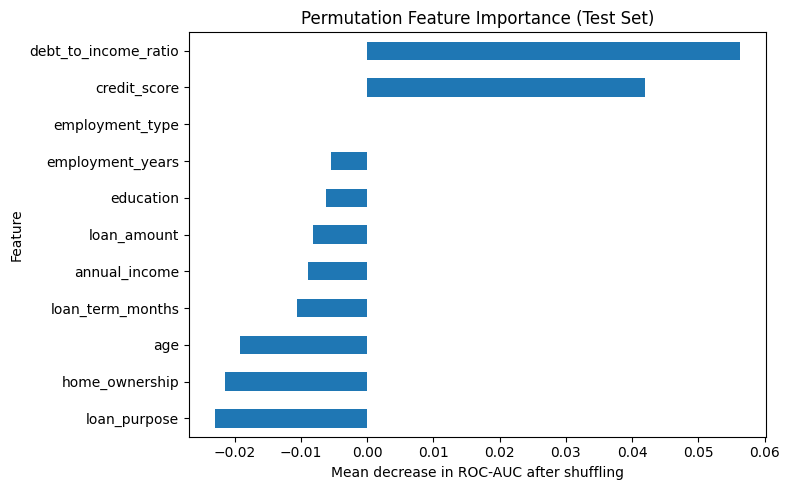

In [11]:
perm = permutation_importance(
    model_pipeline, X_test, y_test,
    n_repeats=8,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1
)
importance_table = (pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False))
display(importance_table.round(4))

importance_table.sort_values("Importance_Mean").plot(
    x="Feature", y="Importance_Mean", kind="barh",
    legend=False, figsize=(8, 5), title="Permutation Feature Importance (Test Set)"
)
plt.xlabel("Mean decrease in ROC-AUC after shuffling")
plt.tight_layout()
plt.show()

## 12. Reuse the trained pipeline for new records
Pass a DataFrame with the same raw input columns. The pipeline automatically applies the learned imputers, scaling, and encoding.

In [12]:
sample_records = X_test.head(3).copy()
sample_predictions = model_pipeline.predict(sample_records)
sample_probabilities = model_pipeline.predict_proba(sample_records)[:, 1]

preview = sample_records.copy()
preview["predicted_default"] = sample_predictions
preview["predicted_default_probability"] = sample_probabilities.round(3)
display(preview)

,age,annual_income,loan_amount,credit_score,employment_years,debt_to_income_ratio,loan_term_months,education,employment_type,home_ownership,loan_purpose,predicted_default,predicted_default_probability
786,22,77945.0,33141.0,718.0,4.9,0.327,36,Graduate,Salaried,Mortgage,Personal,0,0.176
236,54,40461.0,17908.0,613.0,2.7,0.371,36,High School,Self-employed,Own,Vehicle,1,0.509
552,62,18830.0,26997.0,673.0,10.0,0.104,24,Postgraduate,Salaried,Own,Education,0,0.327


## 13. Conclusion
This notebook demonstrates a reusable Scikit-Learn `Pipeline` and `ColumnTransformer`. Splitting before fitting preprocessing steps helps prevent leakage from the test set. Numerical and categorical missing values are imputed separately, numerical features are standardized, and categorical features are one-hot encoded.

**Limitations:** This is a synthetic teaching dataset. Metrics are illustrative and must not be interpreted as real-world credit-risk performance. A production system would require representative validated data, fairness assessment, calibration, monitoring, privacy controls, and human oversight.